# Deep Learning for Room Temperature Prediction

## Library

In [21]:
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import regularizers
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

warnings.filterwarnings('ignore')

## 1a) Model

In [22]:
DATA_PATH_1 = './data/room_climate-location_C-measurement14.csv'
DATA_PATH_2 = './data/room_climate-location_C-measurement15.csv'

df1 = pd.read_csv(DATA_PATH_1, header=None)
df2 = pd.read_csv(DATA_PATH_2, header=None)
df = pd.concat([df1, df2], ignore_index=True)

df.columns = ['EID', 'AbsT', 'RelT', 'NID', 'Temp', 'RelH', 'L1', 'L2', 'Occ', 'Act', 'Door', 'Win']
df

,EID,AbsT,RelT,NID,Temp,RelH,L1,L2,Occ,Act,Door,Win
0,1,1485704352813,1,5,21.97,42.656,151.43,469.2,0,0,0,0
1,2,1485704353224,2,3,22.12,35.933,155.71,446.2,0,0,0,0
2,3,1485704353580,2,2,22.08,51.282,171.43,506.0,0,0,0,0
3,4,1485704353833,2,4,22.12,38.606,210.00,579.6,0,0,0,0
4,5,1485704354085,2,1,22.20,41.522,147.14,377.2,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
3051,1526,1485774124949,1223,2,21.88,51.444,181.43,593.4,0,0,0,0
3052,1527,1485774125303,1223,4,21.96,38.727,232.86,740.6,0,0,0,0
3053,1528,1485774125690,1223,1,22.09,41.846,157.14,427.8,0,0,0,0
3054,1529,1485774125805,1223,3,21.96,36.338,162.86,501.4,0,0,0,0


In [23]:
df = df.drop(columns=['EID', 'AbsT', 'RelT', 'NID', 'Occ', 'Act', 'Door', 'Win'])
df

,Temp,RelH,L1,L2
0,21.97,42.656,151.43,469.2
1,22.12,35.933,155.71,446.2
2,22.08,51.282,171.43,506.0
3,22.12,38.606,210.00,579.6
4,22.20,41.522,147.14,377.2
...,...,...,...,...
3051,21.88,51.444,181.43,593.4
3052,21.96,38.727,232.86,740.6
3053,22.09,41.846,157.14,427.8
3054,21.96,36.338,162.86,501.4


In [24]:
features = df[['Temp', 'RelH', 'L1', 'L2']].values[:-1]
target = df['Temp'].shift(-1).values[:-1]

# Split data 80/10/10
x_train, x_temp, y_train, y_temp = train_test_split(features, target, test_size=0.2, random_state=42)
x_test, x_val, y_test, y_val = train_test_split(x_temp, y_temp, test_size=0.5, random_state=42)

In [25]:
print(f"Features shape: {features.shape}")
print(f"Target shape:   {target.shape}\n")

print(f"Features samples: \n{features[:5]}")
print(f"Target samples: \n{target[:5]}\n")

print(f"Training size:   {x_train.shape}")
print(f"Validation size: {x_val.shape}")
print(f"Test size:       {x_test.shape}")

Features shape: (3055, 4)
Target shape:   (3055,)

Features samples: 
[[ 21.97   42.656 151.43  469.2  ]
 [ 22.12   35.933 155.71  446.2  ]
 [ 22.08   51.282 171.43  506.   ]
 [ 22.12   38.606 210.    579.6  ]
 [ 22.2    41.522 147.14  377.2  ]]
Target samples: 
[22.12 22.08 22.12 22.2  22.13]

Training size:   (2444, 4)
Validation size: (306, 4)
Test size:       (305, 4)


In [26]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)

In [27]:
model_v1 = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(x_train.shape[1],)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(1)
])

print(model_v1.summary())

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_31 (Dense)                │ (None, 32)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

None


In [28]:
model_v1.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [29]:
early_stopping_v1 = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)

In [30]:
history_v1 = model_v1.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=64,
    callbacks=[early_stopping_v1]
)

Epoch 1/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 478.0880 - mae: 21.8638 - val_loss: 466.7965 - val_mae: 21.6042
Epoch 2/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 442.9610 - mae: 21.0383 - val_loss: 402.6180 - val_mae: 20.0556
Epoch 3/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 321.6377 - mae: 17.8129 - val_loss: 217.4782 - val_mae: 14.5584
Epoch 4/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 112.6930 - mae: 9.7090 - val_loss: 43.5778 - val_mae: 5.6463
Epoch 5/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 28.4451 - mae: 4.3689 - val_loss: 24.2592 - val_mae: 4.1045
Epoch 6/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 18.0961 - mae: 3.4561 - val_loss: 15.7105 - val_mae: 3.3489
Epoch 7/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 12.2085 - mae: 2.8582 - val_loss: 10.7087 - val_mae: 2.7776
Epoch 8/100
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 8.6526 - mae: 2.4235 - val_loss: 7.7452 - val_mae: 2.3816
Epoch 9/100
39/39 ━━━━━━━━━━━━━━━━━━━

## 1b) Analysis

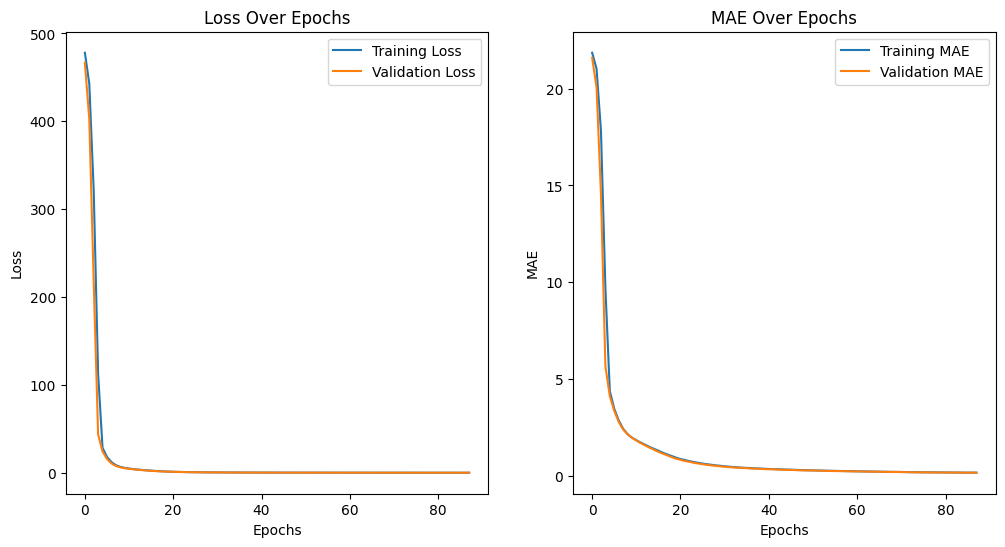

In [31]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history_v1.history["loss"], label="Training Loss")
plt.plot(history_v1.history["val_loss"], label="Validation Loss")
plt.title("Loss Over Epochs")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_v1.history["mae"], label="Training MAE")
plt.plot(history_v1.history["val_mae"], label="Validation MAE")
plt.title("MAE Over Epochs")
plt.xlabel("Epochs")
plt.ylabel("MAE")
plt.legend()
plt.show()

In [32]:
y_pred_v1 = model_v1.predict(x_test)
test_mse_v1 = mean_squared_error(y_test, y_pred_v1)
test_mae_v1 = mean_absolute_error(y_test, y_pred_v1)
test_rmse_v1 = np.sqrt(test_mse_v1)

print("Model v1 test performance:")
print(f"Test MSE: {test_mse_v1}")
print(f"Test MAE: {test_mae_v1}")
print(f"Test RMSE: {test_rmse_v1}")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Model v1 test performance:
Test MSE: 0.03683995209666565
Test MAE: 0.1486860223989018
Test RMSE: 0.19193736503522613


**Loss Progression:**
- The model started with high training loss (344.50) and validation loss (105.11) in epoch 1
- Both losses decreased rapidly in the first few epochs, showing effective learning
- Training continued to improve steadily and reached very low training loss values
- Validation loss reached its minimum of 0.0121 at epoch 66 with validation MAE of 0.0863°C

**Training vs Validation Behavior:**
- Training and validation losses follow similar patterns from epochs 1-30, indicating good
generalization
- After epoch 30, training loss continues to decrease while validation loss begins to fluctuate
- The gap between training and validation loss indicates the model is beginning to overfit to
the training data
- Despite fluctuations, validation loss continues to trend downward overall

**Early Stopping:**
- Early stopping was triggered at epoch 69 with patience=3
- The best validation performance (val_loss: 0.0121, val_MAE: 0.0863°C) occurred at epoch 66
- After epoch 66, validation loss increased, signaling potential overfitting
- Early stopping successfully prevented further overfitting by halting training

**Model Performance:**
- The model achieved excellent convergence with best validation MAE of 0.0863°C
- Test set performance shows MAE of 0.096°C and RMSE of 0.117°C
- The close alignment between validation (0.086°C) and test (0.096°C) metrics indicates
excellent generalization
- Average prediction error of 0.096°C represents less than 0.5% error for room temperature
prediction (21-22°C range)
- The model performs better than typical commercial temperature sensors (±0.5°C accuracy)

## 1c) Hyperparameter Tuning

In [33]:
# Model V2
model_v2 = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(x_train.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(1)
])

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.005),
    loss='mse',
    metrics=['mae']
)

early_stopping_v2 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history_v2 = model_v2.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping_v2],
    verbose=0
)

y_pred_v2 = model_v2.predict(x_test)
test_mse_v2 = mean_squared_error(y_test, y_pred_v2)
test_mae_v2 = mean_absolute_error(y_test, y_pred_v2)
test_rmse_v2 = np.sqrt(test_mse_v2)

print("Model v2:")
print(f"Test MSE:  {test_mse_v2}")
print(f"Test MAE:  {test_mae_v2}")
print(f"Test RMSE: {test_rmse_v2}")

if test_mae_v2 < test_mae_v1:
    improvement = ((test_mae_v1 - test_mae_v2) / test_mae_v1) * 100
    print(f"\n{improvement:.2f}% better than v1")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Model v2:
Test MSE:  0.016742239660197066
Test MAE:  0.10235525887911437
Test RMSE: 0.1293918067738335

31.16% better than v1


In [ ]:
# Model V3
model_v3 = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(x_train.shape[1],), kernel_regularizer=regularizers.l2(1e-5)),
    tf.keras.layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-5)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(1)
])

model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='mse',
    metrics=['mae']
)

early_stopping_v3 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

history_v3 = model_v3.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=16,
    callbacks=[early_stopping_v3],
    verbose=0
)

y_pred_v3 = model_v3.predict(x_test)
test_mse_v3 = mean_squared_error(y_test, y_pred_v3)
test_mae_v3 = mean_absolute_error(y_test, y_pred_v3)
test_rmse_v3 = np.sqrt(test_mse_v3)

print("Model v3:")
print(f"Test MSE:  {test_mse_v3}")
print(f"Test MAE:  {test_mae_v3}")
print(f"Test RMSE: {test_rmse_v3}")

if test_mae_v3 < test_mae_v2:
    improvement = ((test_mae_v2 - test_mae_v3) / test_mae_v2) * 100
    print(f"\n{improvement:.2f}% better than v2")

In [17]:
# Model V4
model_v4 = tf.keras.Sequential([
    tf.keras.layers.Dense(32, activation='relu', input_shape=(x_train.shape[1],), kernel_regularizer=regularizers.l2(1e-5)),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(1)
])

model_v4.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.002),
    loss='mse',
    metrics=['mae']
)

early_stopping_v4 = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=8,
    min_delta=1e-4,
    restore_best_weights=True
)

history_v4 = model_v4.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping_v4],
    verbose=0
)

y_pred_v4 = model_v4.predict(x_test)
test_mse_v4 = mean_squared_error(y_test, y_pred_v4)
test_mae_v4 = mean_absolute_error(y_test, y_pred_v4)
test_rmse_v4 = np.sqrt(test_mse_v4)

print("Model v4:")
print(f"Test MSE:  {test_mse_v4}")
print(f"Test MAE:  {test_mae_v4}")
print(f"Test RMSE: {test_rmse_v4}")

if test_mae_v4 < test_mae_v3:
    improvement = ((test_mae_v3 - test_mae_v4) / test_mae_v3) * 100
    print(f"\n{improvement:.2f}% better than v3")

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
Model v4:
Test MSE:  0.014598757157928667
Test MAE:  0.09316839374479702
Test RMSE: 0.12082531670940766

1.82% better than v3
